In [1]:
!pip install -q torchinfo
!pip install -q segmentation-models-pytorch

In [25]:
import os
import tqdm
import glob
import numpy as np
import pandas as pd
from math import sqrt
from PIL import Image
from easydict import EasyDict
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Subset


from torchvision.models import resnet50, ResNet50_Weights
from torchvision import tv_tensors
from torchvision.transforms import v2

import segmentation_models_pytorch as smp

from sklearn.model_selection import GroupShuffleSplit
from torchinfo import summary
from accelerate import Accelerator

In [3]:
DATA_DIR = "/kaggle/input/competitions/uw-madison-gi-tract-image-segmentation"
image_paths = glob.glob(f'{DATA_DIR}/train/*/*/*/*.png')
df = pd.read_csv(f'{DATA_DIR}/train.csv')

In [4]:
print(f'# seg: {len(df)}')
n_cases = len(np.unique([x.split('/')[-1] for x in glob.glob(f'{DATA_DIR}/train/*')]))
print(f'# cases: {n_cases}')
print(f'# id: {df['id'].nunique()}')
print(f'# classes: {df['class'].nunique()}')
print(f'# segmentaions(not null): {(df['segmentation'].isna() == False).sum()}')
print(f'# class details')
print(f'{df[~df['segmentation'].isna()]['class'].value_counts()}')

print(f'# images: {len(image_paths)}')
shape = np.array(Image.open(image_paths[0]), dtype=np.float32).shape
print(f'# (H, W): {shape}')

# seg: 115488
# cases: 85
# id: 38496
# classes: 3
# segmentaions(not null): 33913
# class details
class
large_bowel    14085
small_bowel    11201
stomach         8627
Name: count, dtype: int64
# images: 38496
# (H, W): (266, 266)


In [5]:
df = df.pivot_table(values='segmentation', index='id', columns='class', aggfunc='first').reset_index()
df['case'] = df['id'].apply(lambda x: x.split('_')[0])
df['id_split'] = df['id'].str.split('_')
df['path_dummy'] = df['id_split'].apply(lambda x: f"/train/{x[0]}/{'_'.join(x[:2])}/scans/{'_'.join(x[-2:])}")
df['path'] = df['path_dummy'].apply(lambda x: glob.glob(f'{DATA_DIR}{x}*.png')[0])
df.drop(columns=['id_split', 'path_dummy'], inplace=True)

### 하이퍼파라미터

In [6]:
classes = ['large_bowel', 'small_bowel', 'stomach']
num_classes = len(classes)

In [7]:
hyperparams = EasyDict({
    'epochs': 10,
    'lr': 1e-3,
    'batch_size': 8
})

In [8]:
# 난수 생성
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [9]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'device: {device}')

device: cuda


### 데이터셋 생성

In [10]:
class UWDataset(Dataset):
    def __init__(self, df, transforms):
        super().__init__()
        self.df = df
        self.transforms = transforms
        self.classes = ['large_bowel', 'small_bowel', 'stomach']

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        sample = self.df.iloc[idx]
        image = Image.open(sample['path'])
        image = np.array(image, dtype=np.float32)
        mask = self.rle_decode(sample[self.classes], image.shape)

        # 중요!!!!
        # 이미지와 마스크를 일관되고 안전하게 처리하기 위해 tv_tenseor 사용
        image = tv_tensors.Image(image)
        mask = tv_tensors.Mask(mask)

        image, mask = self.transforms(image, mask)
        mask = mask.int()
        return image, mask

    def rle_decode(self, segments, img_size):
        mask = torch.zeros(3, img_size[0]* img_size[1], dtype=torch.int32)

        for i, segment in enumerate(segments):
            if str(segment) != 'nan':
                segment = segment.split()
                starts = np.array(segment[::2], dtype=np.int32) - 1
                ends = starts + np.array(segment[1::2], dtype=np.int32)
                for start, end in zip(starts, ends):
                    mask[i, start:end] = 1

        return mask.reshape((3, img_size[0], img_size[1]))

In [11]:
# 중요!!!!
# 이미지, 마스크를 안전하게 처리하기 위해 v2 사용
train_transforms = v2.Compose([
    v2.Resize(size=(234,), antialias=True),
    v2.RandomCrop(size=(224, 224)),
    v2.RandomPhotometricDistort(p=0.5),
    v2.RandomHorizontalFlip(p=0.5),
    v2.Lambda(lambda x: (x - x.min()) / (x.max() - x.min() + 1e-8)),
    v2.Normalize(mean=(0.5,), std=(0.5,)),
    # 1채널 grayscale -> 3채널 RGB
    v2.Lambda(lambda x: x.repeat(3, 1, 1))
])
val_transforms = v2.Compose([
    v2.Resize(size=(224, 224), antialias=True),
    v2.Lambda(lambda x: (x - x.min()) / (x.max() - x.min() + 1e-8)),
    v2.Normalize(mean=(0.5,), std=(0.5,)),
    v2.Lambda(lambda x: x.repeat(3, 1, 1))
])

In [12]:
train_dataset = UWDataset(df=df, transforms=train_transforms)
val_dataset = UWDataset(df=df, transforms=val_transforms)

gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, val_idx = next(gss.split(df, groups=df['case']))

train_dataset = Subset(train_dataset, indices=train_idx)
val_dataset = Subset(val_dataset, indices=val_idx)

train_loader = DataLoader(train_dataset, batch_size=hyperparams['batch_size'], shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=hyperparams['batch_size'], shuffle=False)

In [13]:
first_batch = next(iter(train_loader))
print(f'Image size: {first_batch[0].shape}')
print(f'Mask size: {first_batch[1].shape}')

Image size: torch.Size([8, 3, 224, 224])
Mask size: torch.Size([8, 3, 224, 224])


### 모델

#### 1. UNet

In [14]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        # 뒤에 BatchNorm2d가 바로 따라오므로 Conv2d의 bias는 불필요하여 False로 설정
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=3, base=32):
        super().__init__()

        # ============================================================
        # 1. Encoder
        # ============================================================
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.enc4 = DoubleConv(base * 4, base * 8)

        # 다운샘플링(maxpooling)
        self.maxpool = nn.MaxPool2d(2)

        # ============================================================
        # 2. Bottleneck
        # ============================================================
        self.bottleneck = DoubleConv(base * 8, base * 16)

        # ============================================================
        # 3. Decoder
            # upsampling(nn.ConvTranspose2d)
            # skip connection(concat)
            # Conv(채널 수를 반으로 축소)
        # ============================================================
        self.up4 = nn.ConvTranspose2d(base * 16, base * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)

        # ============================================================
        # 4. Header: 1x1 conv로 최종 픽셀별 logit 산출
        # ============================================================
        self.head = nn.Conv2d(base, out_ch, kernel_size=1)

    def forward(self, x):
        # 1. Encoder
        skip1 = self.enc1(x)
        skip2 = self.enc2(self.maxpool(skip1))
        skip3 = self.enc3(self.maxpool(skip2))
        skip4 = self.enc4(self.maxpool(skip3))

        # 2. Bottleneck
        output = self.bottleneck(self.maxpool(skip4))

        # 3. Decoder
        up4 = self.up4(output)
        # print(f'output {output.shape}')
        # print(f'up4 {up4.shape}')
        # print(f'skip4 {skip4.shape}')
        merged4 = torch.cat([up4, skip4], dim=1)
        dec4 = self.dec4(merged4)

        up3 = self.up3(dec4)
        merged3 = torch.cat([up3, skip3], dim=1)
        dec3 = self.dec3(merged3)

        up2 = self.up2(dec3)
        merged2 = torch.cat([up2, skip2], dim=1)
        dec2 = self.dec2(merged2)

        up1 = self.up1(dec2)
        merged1 = torch.cat([up1, skip1], dim=1)
        dec1 = self.dec1(merged1)

        # 4. Header
        out = self.head(dec1)
        return out

#### 2. Deeplabv3+

In [15]:
class ConvBnReLU(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, d=1):
        super().__init__()
        # w, h 크기 그대로 유지하기 위해 패딩 크기 조절
        # 3×3 커널은 "팽창률 d만큼 패딩"해야 출력 크기가 입력과 같게 유지됨
        p = 0 if k == 1 else d
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=k, padding=p, dilation=d, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)

class ASPP(nn.Module):
    '''
    인코더를 통해 추출된 feature map을 다양한 크기의 dilation rate로 특징을 추출함
    1. 각각 병렬적으로 수행(in_ch -> out_ch)
        - 1x1 Conv
        - dilated Conv(d=6)
        - dilated Conv(d=12)
        - dilated Conv(d=18)
        - GAP
    2. Concat -> Conv(out_ch*5 -> out_ch)
    '''
    def __init__(self, in_ch, out_ch, rates=[6, 12, 18]):
        super().__init__()
        self.branches = nn.ModuleList([
            # 1x1 Conv
            ConvBnReLU(in_ch, out_ch, k=1),
            # Dilated Conv(d=6, 12, 18)
            *[ConvBnReLU(in_ch, out_ch, k=3, d=r) for r in rates]
        ])

        # Global Average Pooling(GAP)
        self.gap = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            ConvBnReLU(in_ch, out_ch, k=1)
        )

        self.project = nn.Sequential(
            ConvBnReLU(out_ch * 5, out_ch, k=1),
            nn.Dropout(0.1)
        )


    def forward(self, x):
        h, w = x.shape[-2:]
        maps = [b(x) for b in self.branches]
        # GAP를 통과한 1x1을 hxw로 upsamplinmg(bilinear)
        gap = F.interpolate(self.gap(x), size=(h, w), mode='bilinear', align_corners=False)
        return self.project(torch.cat(maps + [gap], dim=1))


class DeepLabV3Plus(nn.Module):
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        # 1. Encoder: pretrained ResNet50
        weights = ResNet50_Weights.IMAGENET1K_V1 if pretrained == True else None
        backbone = resnet50(weights=weights, replace_stride_with_dilation=[False, False, True])

        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool
        )
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        # 2. ASPP
        self.aspp = ASPP(backbone.layer4[0].conv3.out_channels, 256)
        # skip 으로 오는 layer1(256채널)을 48채널로 줄입니다. 채널이 너무 많으면 ASPP의 풍부한 정보(256채널)를 압도하기 때문입니다.
        self.low = ConvBnReLU(256, 48, k=1)

        # 3. Decoder: concat(256+48) -> 3x3 conv 2번
        self.decoder = nn.Sequential(
            ConvBnReLU(256+48, 256, k=3),
            ConvBnReLU(256, 256, k=3)
        )

        # 4. Header: 1x1 conv 픽셀마다 num_classes 개의 로짓 산출
        self.head = nn.Conv2d(256, num_classes, 1)

    def forward(self, x):
        h, w = x.shape[-2:]

        # 1. 인코더
        x = self.stem(x)        # 1/4
        skip = self.layer1(x)   # 1/4
        x = self.layer2(skip)   # 1/8
        x = self.layer3(x)      # 1/16
        x = self.layer4(x)      # 1/16(dilation)

        # 2. ASPP
        x = self.aspp(x)

        # 3. 디코더
            # ASPP output upsampling
            # skip connection(layer1 output)
            # decoder
        x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
        x = self.decoder(torch.concat([x, self.low(skip)], dim=1))

        # 4. 헤더
        x = self.head(x)
        # 입력과 같은 크기로 반환
        return F.interpolate(x, size=(h, w), mode='bilinear', align_corners=False)


#### 3. SegFormer

In [41]:
from functools import partial
from einops import rearrange

def cast_tuple(val, depth):
    return val if isinstance(val, tuple) else (val,) * depth

class DsConv2d(nn.Module):
    def __init__(self, dim_in, dim_out, kernel_size, padding, stride=1, bias=True):
        super().__init__()
        self.net = nn.Sequential(
            # Depthwise conv(group conv with num_groups=in_channels)
            nn.Conv2d(dim_in, dim_in, kernel_size=kernel_size,
                      stride=stride, padding=padding, groups=dim_in, bias=bias),
            # Pointwise conv
            nn.Conv2d(dim_in, dim_out, 1, bias=bias)
        )

    def forward(self, x):
        return self.net(x)

class LayerNorm(nn.Module):
    def __init__(self, dim, eps = 1e-5):
        super().__init__()
        self.eps = eps
        self.g = nn.Parameter(torch.ones(1, dim, 1, 1))
        self.b = nn.Parameter(torch.zeros(1, dim, 1, 1))

    def forward(self, x):
        std = torch.var(x, dim = 1, unbiased = False, keepdim = True).sqrt()
        mean = torch.mean(x, dim = 1, keepdim = True)
        return (x - mean) / (std + self.eps) * self.g + self.b

class PreNorm(nn.Module):
    '''
    Layer Normalization을 self-attention,FF 앞에서 함
    '''
    def __init__(self, dim, fn):
        super().__init__()
        self.fn = fn
        self.norm = LayerNorm(dim)

    def forward(self, x):
        return self.fn(self.norm(x))

class EfficientSelfAttention(nn.Module):
    def __init__(self, dim, heads, reduction_ratio):
        super().__init__()
        self.scale = (dim // heads) ** -0.5
        self.heads = heads

        self.to_q = nn.Conv2d(dim, dim, 1, bias=False)
        self.to_kv = nn.Conv2d(dim, dim * 2, reduction_ratio, stride=reduction_ratio, bias=False)
        self.to_out = nn.Conv2d(dim, dim, 1, bias=False)

    def forward(self, x):
        h, w = x.shape[-2:]
        heads = self.heads

        # 모든 헤드의 어텐션 연산을 단 한 번의 행렬곱(einsum)으로 동시에 병렬처리
        q = self.to_q(x)
        k, v = self.to_kv(x).chunk(2, dim=1)
        q, k, v = map(lambda t: rearrange(t, 'b (h c) x y -> (b h) (x y) c', h=heads), (q, k, v))

        # QK_transposed 연산
        sim = torch.einsum('b i d, b j d -> b i j', q, k) * self.scale
        # attenstion score 계산
        attn = sim.softmax(dim=-1)

        # attention score * V
        out = torch.einsum('b i j, b j d -> b i d', attn, v)
        out = rearrange(out, '(b h) (x y) c -> b (h c) x y', h=heads, x=h, y=w)
        return self.to_out(out)

class MixFeedForward(nn.Module):
    def __init__(self, dim, expansion_factor):
        super().__init__()
        hidden_dim = dim * expansion_factor
        self.net = nn.Sequential(
            # 1x1 conv로 채널 수 늘렸다가 다시 줄이는 inverted bottleneck
            nn.Conv2d(dim, hidden_dim, 1),
            # Depthwise separable conv
            DsConv2d(hidden_dim, hidden_dim, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(hidden_dim, dim, 1)
        )

    def forward(self, x):
        return self.net(x)

class MiT(nn.Module):
    '''
    SegFormer의 인코더로 4개의 stage로 구성
    각 stage는 다음으로 구성됨
        - Overlap Patch Merging: 슬라이딩 윈도우로 이미지를 겹치게 훑으면서 patch merging
        - Efficient self-attention: k,v의 크기를 reduction ratio만큼 줄여 computation/memory 비용 줄임
        - Mix feed forward: positional encoding 없이 Depthwise separable conv(3x3)으로 대신함
    '''
    def __init__(self,
                 channels,
                 dims,
                 heads,
                 ff_expansion,
                 reduction_ratio,
                 num_layers):
        super().__init__()
        stage_kernel_stride_pad = ((7, 4, 3), (3, 2, 1), (3, 2, 1), (3, 2, 1))

        dims = (channels, *dims)
        dim_pairs = list(zip(dims[:-1], dims[1:]))

        self.stages = nn.ModuleList([])

        for (dim_in, dim_out), (kernel, stride, padding), num_layers, ff_expansion, heads, reduction_ratio in zip(dim_pairs, stage_kernel_stride_pad, num_layers, ff_expansion, heads, reduction_ratio):
            # Overlap Patch Merging
            # 슬라이딩 윈도우로 이미지를 겹치게 훑으면서 patchify하고 각 패치를 1차원 배열로 펼쳐서 출력함
            # 출력 텐서 모양: (B, 패치 하나의 모든 픽셀 수 ,패치 개수)
            get_overlap_patches = nn.Unfold(kernel, stride = stride, padding = padding)
            # Patch embedding
            overlap_patch_embed = nn.Conv2d(dim_in * kernel ** 2, dim_out, 1)

            layers = nn.ModuleList([])

            for _ in range(num_layers):
                layers.append(nn.ModuleList([
                    PreNorm(dim_out, EfficientSelfAttention(dim=dim_out, heads=heads, reduction_ratio=reduction_ratio)),
                    PreNorm(dim_out, MixFeedForward(dim=dim_out, expansion_factor=ff_expansion))
                ]))

            self.stages.append(nn.ModuleList([
                get_overlap_patches,
                overlap_patch_embed,
                layers
            ]))

    def forward(self, x, return_layer_outputs=False):
        h, w = x.shape[-2:]

        layer_outputs = []
        for (get_overlap_patches, overlap_embed, layers) in self.stages:
            # Overlap Patch Merging
            # x: (B, C, 패치개수)
            x = get_overlap_patches(x)

            num_patches = x.shape[-1]
            # 원래 (h,w)에서 (num_patches**1/2, num_patches**1/2)로 얼마나 줄었나
            ratio = int(sqrt((h*w) / num_patches))
            # 패치 임베딩(1x1 conv)을 위해 (B, C, H, W)로 reshape
            x = rearrange(x, 'b c (h w) -> b c h w', h=h//ratio)

            # Patch Embedding
            x = overlap_embed(x)

            for (attn, ff) in layers:
                # Efficient self attention(LN + skip)
                x = attn(x) + x
                # Mix FF(LN + skip)
                x = ff(x) + x

            layer_outputs.append(x)
        ret = x if not return_layer_outputs else layer_outputs
        return ret


class SegFormer(nn.Module):
    def __init__(self,
                 dims=(32, 64, 160, 256),
                 heads=(1, 2, 5, 8),
                 ff_expansion=(8, 8, 4, 4),
                 reduction_ratio=(8, 4, 2, 1),
                 num_layers=2,
                 channels=3,
                 decoder_dim=256,
                 num_classes=3):
        super().__init__()
        dims, heads, ff_expansion, reduction_ratio, num_layers = map(partial(cast_tuple, depth = 4), (dims, heads, ff_expansion, reduction_ratio, num_layers))
        assert all([*map(lambda t: len(t) == 4, (dims, heads, ff_expansion, reduction_ratio, num_layers))]), 'only four stages are allowed, all keyword arguments must be either a single value or a tuple of 4 values'
        
        # 인코더
        self.mit = MiT(
            channels=channels,
            dims=dims,
            heads=heads,
            ff_expansion=ff_expansion,
            reduction_ratio=reduction_ratio,
            num_layers=num_layers
        )

        # 디코더
        # 인코더의 4개의 stage에서 나온 값을 동일한 채널과 크기로 맞춰주기
        self.to_fused = nn.ModuleList([nn.Sequential(
            nn.Conv2d(dim, decoder_dim, 1),
            nn.Upsample(scale_factor = 2 ** i)
        ) for i, dim in enumerate(dims)])

        # 최종 마스크 예측
        self.to_segmentation = nn.Sequential(
            nn.Conv2d(4 * decoder_dim, decoder_dim, 1),
            nn.Conv2d(decoder_dim, num_classes, 1),
        )


    def forward(self, x):
        input_shape = x.shape[-2:]
        # 인코더
        layer_outputs = self.mit(x, return_layer_outputs = True)

        # 인코더(4 stage output채널 및 크기 통일)
        fused = [to_fused(output) for output, to_fused in zip(layer_outputs, self.to_fused)]
        # 채널 축으로 concat
        fused = torch.cat(fused, dim = 1)
        # 헤더: segmentation map 산출
        out = self.to_segmentation(fused)

        # 1/4크기인 마스크를 원본 입력 크기로 확대
        out = nn.functional.interpolate(out, size=input_shape, mode='bilinear', align_corners=False)
        return out

### 손실함수: BCE + Dice loss

In [17]:
def bce_dice_loss(logits, target):
    # logits/target: (B, 3, H, W) -> F.binary_cross_entropy_with_logits
    # logits: (B, 3, H, W) / target: (B, H, W) 픽셀마다 클래스가 들어간 경우 -> F.cross_entropy
    # 1. Cross Entropy
    target = target.float()
    bce = F.binary_cross_entropy_with_logits(logits, target)

    # 2. Dice loss
    # soft dice: softmax
    pred = torch.sigmoid(logits)

    inter = (pred * target).sum(dim=(0, 2, 3))
    union = pred.sum(dim=(0, 2, 3)) + target.sum(dim=(0, 2, 3))

    dice_score = (2 * inter + 1) / (union + 1)
    # 클래스별 평균 dice loss
    dice_loss = 1 - dice_score.mean()
    return bce + dice_loss


### 평가 지표: Dice, IoU

In [18]:
@torch.no_grad()
def eval_metrics(model, loader):
    model.eval()

    num_classes = 3  # large_bowel, small_bowel, stomach
    inter = torch.zeros(num_classes)       # 겹친 픽셀 수 (교집합)
    union = torch.zeros(num_classes)       # 합친 픽셀 수 (합집합)
    pred_sum = torch.zeros(num_classes)    # 예측이 칠한 픽셀 수
    tgt_sum = torch.zeros(num_classes)     # 정답이 칠한 픽셀 수

    val_loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = bce_dice_loss(logits, y)
        val_loss += loss.item() * x.size(0)
        pred = (torch.sigmoid(logits) > 0.5).float()
        y = y.float()

        for c in range(num_classes):
            pred_c = pred[:, c]  # 특정 장기 예측 마스크 (B, H, W)
            tgt_c = y[:, c]  # 특정 장기 정답 마스크 (B, H, W)

            inter[c] += (pred_c * tgt_c).sum().item()
            union[c] += (
                pred_c.sum().item() + tgt_c.sum().item() - (pred_c * tgt_c).sum().item()
            )
            pred_sum[c] += pred_c.sum().item()
            tgt_sum[c] += tgt_c.sum().item()

    # 1e-6을 더해 0으로 나누어지는 에러 방지
    smooth = 1e-6
    dice = (2.0 * inter + smooth) / (pred_sum + tgt_sum + smooth)
    iou = (inter + smooth) / (union + smooth)

    # 검증 세트 내에 실제로 한 픽셀이라도 존재하는 클래스만 평균에 포함
    present = [c for c in range(num_classes) if tgt_sum[c] > 0]

    metric = {
                'dice': float(dice[present].mean()) if present else 0.0,
                'iou': float(iou[present].mean()) if present else 0.0,
            }

    return val_loss, metric


### 학습

In [62]:
# 모델 불러오기
def get_model(model_name, num_classes=3, device='cuda'):
    # From scratch
    if model_name == 'UNet':
        model = UNet(in_ch=3, out_ch=num_classes, base=16)
    elif model_name == 'DeepLabV3Plus':
        model = DeepLabV3Plus(num_classes=num_classes, pretrained=False)
    elif model_name == 'SegFormer':
        model = SegFormer()
    # segmentation_models_pytorch(smp, 사전훈련된 모델 활용)
    elif model_name == 'UNet(smp)':
        model = smp.UNet('resnet50',
                         encoder_weights='imagenet',
                         in_channels=3,
                         classes=3)
    elif model_name == 'DeepLabV3Plus(smp)':
        model = smp.DeepLabV3Plus('resnet50',
                                  encoder_weights='imagenet',
                                  in_channels=3,
                                  classes=3)
    elif model_name == 'SegFormer(smp)':
        model = smp.Segformer('resnet50',
                              encoder_weights='imagenet',
                              in_channels=3,
                              classes=3)
    return model.to(device)

In [27]:
def train(model_name,
          train_loader,
          val_loader,
          epochs,
          lr,
          device):
    print(f"{'='*30} {model_name} {'='*30}")
    model = get_model(model_name)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    accelerator = Accelerator()
    model, optimizer, train_loader = accelerator.prepare(
        model, optimizer, train_loader
    )

    best_dice = 0.0
    model_path = ''

    loss_train_hist = []
    loss_valid_hist = []
    metric_valid_hist = []

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        n = 0

        pbar = tqdm.tqdm(train_loader, desc=f'Epoch [{epoch+1}/{epochs}]', leave=False)
        for x, y, *_ in pbar:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(x)
            loss = bce_dice_loss(logits, y)
            loss.backward()
            optimizer.step()
            train_loss = loss.item() * x.size(0)
            n += x.size(0)
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})
        scheduler.step()
        val_loss, metrics = eval_metrics(model, val_loader)

        loss_train_hist.append(train_loss/n)
        loss_valid_hist.append(val_loss/n)
        metric_valid_hist.append(metrics)
        print(
            f"Epoch [{epoch+1}/{epochs}] | "
            f"Train loss: {train_loss/n:.4f} | "
            f"Valid loss: {val_loss/n:.4f} | "
            f"Val Dice: {metrics['dice']:.4f} | "
            f"Val IoU: {metrics['iou']:.4f}"
        )

        if metrics['dice'] > best_dice:
            best_dice = metrics['dice']
            model_dir = './model'
            model_path = os.path.join(model_dir, f'best_{model_name}.pt')
            os.makedirs(model_dir, exist_ok=True)
            torch.save(model.state_dict(), model_path)

    print(f'Best val dice: {round(best_dice, 4)}')
    print(f'Saved best model: {model_path}')

    return loss_train_hist, loss_valid_hist, metric_valid_hist


UNet

In [21]:
loss_train_hist_unet, loss_valid_hist_unet, metric_valid_hist_unet = train(model_name='UNet',
                                                                            train_loader=train_loader,
                                                                            val_loader=val_loader,
                                                                            epochs=hyperparams['epochs'],
                                                                            lr=hyperparams['lr'],
                                                                            device=device)

============================== UNet ==============================


Epoch [1/10] | Train loss: 0.0004 | Valid loss: 0.1059 | Val Dice: 0.1155 | Val IoU: 0.0698


Epoch [2/10] | Train loss: 0.0004 | Valid loss: 0.0966 | Val Dice: 0.3462 | Val IoU: 0.2143


Epoch [3/10] | Train loss: 0.0004 | Valid loss: 0.0909 | Val Dice: 0.4433 | Val IoU: 0.2906


Epoch [4/10] | Train loss: 0.0005 | Valid loss: 0.0814 | Val Dice: 0.5536 | Val IoU: 0.3861


Epoch [5/10] | Train loss: 0.0004 | Valid loss: 0.0739 | Val Dice: 0.6195 | Val IoU: 0.4514


Epoch [6/10] | Train loss: 0.0004 | Valid loss: 0.0678 | Val Dice: 0.6913 | Val IoU: 0.5297


Epoch [7/10] | Train loss: 0.0004 | Valid loss: 0.0696 | Val Dice: 0.6655 | Val IoU: 0.5016


Epoch [8/10] | Train loss: 0.0003 | Valid loss: 0.0661 | Val Dice: 0.6955 | Val IoU: 0.5357


Epoch [9/10] | Train loss: 0.0005 | Valid loss: 0.0697 | Val Dice: 0.6596 | Val IoU: 0.4951


Epoch [10/10] | Train loss: 0.0002 | Valid loss: 0.0627 | Val Dice: 0.7258 | Val IoU: 0.5738
Best val dice: 0.7258
Saved best model: ./model/best_UNet.pt


DeepLabV3+

In [28]:
loss_train_hist_deep, loss_valid_hist_deep, metric_valid_hist_deep = train(model_name='DeepLabV3Plus',
                                                                            train_loader=train_loader,
                                                                            val_loader=val_loader,
                                                                            epochs=hyperparams['epochs'],
                                                                            lr=hyperparams['lr'],
                                                                            device=device)

============================== DeepLabV3Plus ==============================


Epoch [1/10] | Train loss: 0.0004 | Valid loss: 0.0994 | Val Dice: 0.3696 | Val IoU: 0.2289


Epoch [2/10] | Train loss: 0.0004 | Valid loss: 0.0856 | Val Dice: 0.5133 | Val IoU: 0.3481


Epoch [3/10] | Train loss: 0.0004 | Valid loss: 0.0785 | Val Dice: 0.5662 | Val IoU: 0.3980


Epoch [4/10] | Train loss: 0.0004 | Valid loss: 0.0738 | Val Dice: 0.6062 | Val IoU: 0.4407


Epoch [5/10] | Train loss: 0.0003 | Valid loss: 0.0780 | Val Dice: 0.5940 | Val IoU: 0.4262


Epoch [6/10] | Train loss: 0.0003 | Valid loss: 0.0746 | Val Dice: 0.5985 | Val IoU: 0.4333


Epoch [7/10] | Train loss: 0.0004 | Valid loss: 0.0700 | Val Dice: 0.6421 | Val IoU: 0.4765


Epoch [8/10] | Train loss: 0.0004 | Valid loss: 0.0671 | Val Dice: 0.6586 | Val IoU: 0.4938


Epoch [9/10] | Train loss: 0.0003 | Valid loss: 0.0641 | Val Dice: 0.6898 | Val IoU: 0.5306


Epoch [10/10] | Train loss: 0.0003 | Valid loss: 0.0676 | Val Dice: 0.6604 | Val IoU: 0.4958
Best val dice: 0.6898
Saved best model: ./model/best_DeepLabV3Plus.pt


SegFormer

In [42]:
loss_train_hist_sf, loss_valid_hist_sf, metric_valid_hist_sf = train(model_name='SegFormer',
                                                                            train_loader=train_loader,
                                                                            val_loader=val_loader,
                                                                            epochs=hyperparams['epochs'],
                                                                            lr=hyperparams['lr'],
                                                                            device=device)

============================== SegFormer ==============================


Epoch [1/10] | Train loss: 0.0019 | Valid loss: 0.3252 | Val Dice: 0.0451 | Val IoU: 0.0232


Epoch [2/10] | Train loss: 0.0005 | Valid loss: 0.1432 | Val Dice: 0.1247 | Val IoU: 0.0667


Epoch [3/10] | Train loss: 0.0005 | Valid loss: 0.1244 | Val Dice: 0.1201 | Val IoU: 0.0641


Epoch [4/10] | Train loss: 0.0004 | Valid loss: 0.1129 | Val Dice: 0.2014 | Val IoU: 0.1131


Epoch [5/10] | Train loss: 0.0011 | Valid loss: 0.2953 | Val Dice: 0.0001 | Val IoU: 0.0001


Epoch [6/10] | Train loss: 0.0005 | Valid loss: 0.1105 | Val Dice: 0.2358 | Val IoU: 0.1351


Epoch [7/10] | Train loss: 0.0005 | Valid loss: 0.1104 | Val Dice: 0.2404 | Val IoU: 0.1392


Epoch [8/10] | Train loss: 0.0005 | Valid loss: 0.1056 | Val Dice: 0.2657 | Val IoU: 0.1554


Epoch [9/10] | Train loss: 0.0004 | Valid loss: 0.1057 | Val Dice: 0.2957 | Val IoU: 0.1755


Epoch [10/10] | Train loss: 0.0005 | Valid loss: 0.1054 | Val Dice: 0.3154 | Val IoU: 0.1894
Best val dice: 0.3154
Saved best model: ./model/best_SegFormer.pt


In [63]:
loss_train_hist_sfsmp, loss_valid_hist_sfsmp, metric_valid_hist_sfsmp = train(model_name='SegFormer(smp)',
                                                                            train_loader=train_loader,
                                                                            val_loader=val_loader,
                                                                            epochs=hyperparams['epochs'],
                                                                            lr=hyperparams['lr'],
                                                                            device=device)

============================== SegFormer(smp) ==============================


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch [1/10] | Train loss: 0.0005 | Valid loss: 0.0797 | Val Dice: 0.5895 | Val IoU: 0.4208


Epoch [2/10] | Train loss: 0.0004 | Valid loss: 0.0743 | Val Dice: 0.6363 | Val IoU: 0.4723


... (4 outputs left out)

Epoch [7/10] | Train loss: 0.0002 | Valid loss: 0.0552 | Val Dice: 0.7523 | Val IoU: 0.6065


Epoch [8/10] | Train loss: 0.0004 | Valid loss: 0.0575 | Val Dice: 0.7482 | Val IoU: 0.6018


Epoch [9/10] | Train loss: 0.0003 | Valid loss: 0.0523 | Val Dice: 0.7804 | Val IoU: 0.6453


Epoch [10/10] | Train loss: 0.0003 | Valid loss: 0.0524 | Val Dice: 0.7778 | Val IoU: 0.6413
Best val dice: 0.7804
Saved best model: ./model/best_SegFormer(smp).pt


### 학습 곡선 시각화

In [65]:
histories = {
    'UNet': {
        'train_loss': loss_train_hist_unet,
        'valid_loss': loss_valid_hist_unet,
        'valid_metric': metric_valid_hist_unet
    },
    'DeepLabV3Plus': {
        'train_loss': loss_train_hist_deep,
        'valid_loss': loss_valid_hist_deep,
        'valid_metric': metric_valid_hist_deep
    },
    'SegFormer': {
        'train_loss': loss_train_hist_sfsmp,
        'valid_loss': loss_valid_hist_sfsmp,
        'valid_metric': metric_valid_hist_sfsmp
    }
}

In [78]:
def plot_model_comparison(model_histories):
  """여러 모델의 학습 히스토리를 받아 비교 그래프를 그려주는 함수

  Args:
      model_histories (dict): {
              '모델이름1': {
                  'train_loss': [...],
                  'valid_loss': [...],
                  'valid_metric': [{'dice': 0.5, 'iou': 0.3}, ...]
              },
              '모델이름2': {
                  'train_loss': [...],
                  'valid_loss': [...],
                  'valid_metric': [{'dice': 0.6, 'iou': 0.4}, ...]
              }
          }
  """
  plt.figure(figsize=(18, 6))

  # --- 1. Loss 비교 그래프 ---
  plt.subplot(1, 3, 1)
  for model_name, hist in model_histories.items():
    epochs = range(len(hist['train_loss']))
    # Train은 점선(--), Validation은 실선(-)으로 표현
    # plt.plot(
    #     epochs,
    #     hist['train_loss'],
    #     linestyle='--',
    #     label=f'{model_name} (Train)',
    # )
    plt.plot(
        epochs,
        hist['valid_loss'],
        linestyle='-',
        label=f'{model_name}',
    )

  plt.title('Validation Loss Comparison')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.grid(True)
  plt.legend()

  # --- 2. 검증 지표(Dice) 비교 그래프 ---
  plt.subplot(1, 3, 2)
  for model_name, hist in model_histories.items():
    epochs = range(len(hist['valid_metric']))
    dice_hist = [m['dice'] for m in hist['valid_metric']]

    # Dice는 실선(-), IoU는 점선(--)으로 표현
    plt.plot(
        epochs, dice_hist, linestyle='-', label=f'{model_name} (Dice)'
    )

  plt.title('Validation Metric Comparison (Dice)')
  plt.xlabel('Epoch')
  plt.ylabel('Metric Score')
  plt.grid(True)
  plt.legend()

      # --- 2. 검증 지표(IoU) 비교 그래프 ---
  plt.subplot(1, 3, 3)
  for model_name, hist in model_histories.items():
    epochs = range(len(hist['valid_metric']))
    iou_hist = [m['iou'] for m in hist['valid_metric']]

    # Dice는 실선(-), IoU는 점선(--)으로 표현
    plt.plot(
        epochs, iou_hist, linestyle='--', label=f'{model_name} (IoU)'
    )

  plt.title('Validation Metric Comparison (IoU)')
  plt.xlabel('Epoch')
  plt.ylabel('Metric Score')
  plt.grid(True)
  plt.legend()

  plt.tight_layout()
  plt.show()

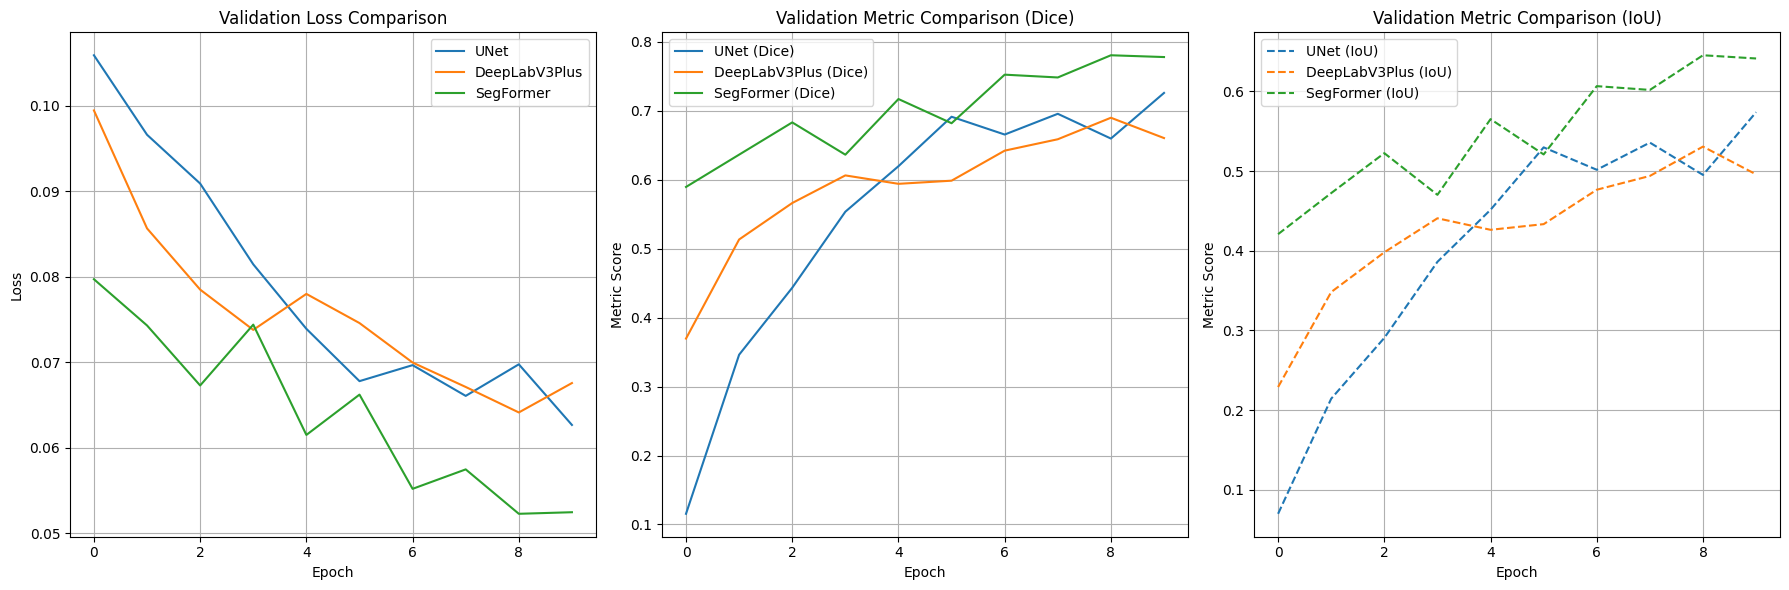

In [79]:
plot_model_comparison(histories)

### 추론 및 시각화

In [44]:
def model_output_show(image, target, output):   #to show MRI image with its mask
    plt.figure(figsize=(18, 6))
    plt.subplot(1, 3, 1)            #View the raw photo
    plt.imshow(image, cmap='gray')
    plt.axis(False)
    plt.title('MRI image')
#-------------------------------------------------------------------------------------------------
    plt.subplot(1, 3, 2)           #View segmented photo
    plt.imshow(image, cmap='gray');
    for i, color in zip(range(3), ['#ffd670', '#f15bb5', '#00f5d4']):#Making masks for each class with designated colors
        cmap = mcolors.ListedColormap(['none', color])
        plt.imshow(target[i, :, :], cmap=cmap, alpha=0.7)

    plt.axis(False);
    plt.title('target');
#--------------------------------------------------------------------------------------------------
    plt.subplot(1, 3, 3)           #View segmented photo
    plt.imshow(image, cmap='gray');
    for i, color in zip(range(3), ['#ffd670', '#f15bb5', '#00f5d4']):#Making masks for each class with designated colors
        cmap = mcolors.ListedColormap(['none', color])
        plt.imshow(output[i, :, :], cmap=cmap, alpha=0.7)

    plt.axis(False);
    plt.title('output');

#---------------------------------------------------------------------------------------------------
    plt.figure(figsize=(2, 1))     #View colorbar and class names
    plt.scatter([], [], c='#ffd670', label='large_bowel', s=100)
    plt.scatter([], [], c='#f15bb5', label='small_bowel', s=100)
    plt.scatter([], [], c='#00f5d4', label='stomach', s=100)
    plt.axis(False)
    plt.legend()
    plt.show()

In [45]:
def segment(image, model):
    with torch.no_grad():
        prediction = model(image)
    return torch.sigmoid(prediction).cpu()

In [74]:
model_unet = get_model('UNet', num_classes=3, device='cuda')
model_unet_path = './model/best_UNet.pt'
model_unet.load_state_dict(torch.load(model_unet_path, map_location='cuda'))
model_unet.eval()

model_deeplabv3 = get_model('DeepLabV3Plus', num_classes=3, device='cuda')
model_deeplabv3_path = './model/best_DeepLabV3Plus.pt'
model_deeplabv3.load_state_dict(torch.load(model_deeplabv3_path, map_location='cuda'))
model_deeplabv3.eval()

model_sf = get_model('SegFormer(smp)', num_classes=3, device='cuda')
model_sf_path = './model/best_SegFormer(smp).pt'
model_sf.load_state_dict(torch.load(model_sf_path, map_location='cuda'))
model_sf.eval()

Segformer(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
 

==================== UNet ====================


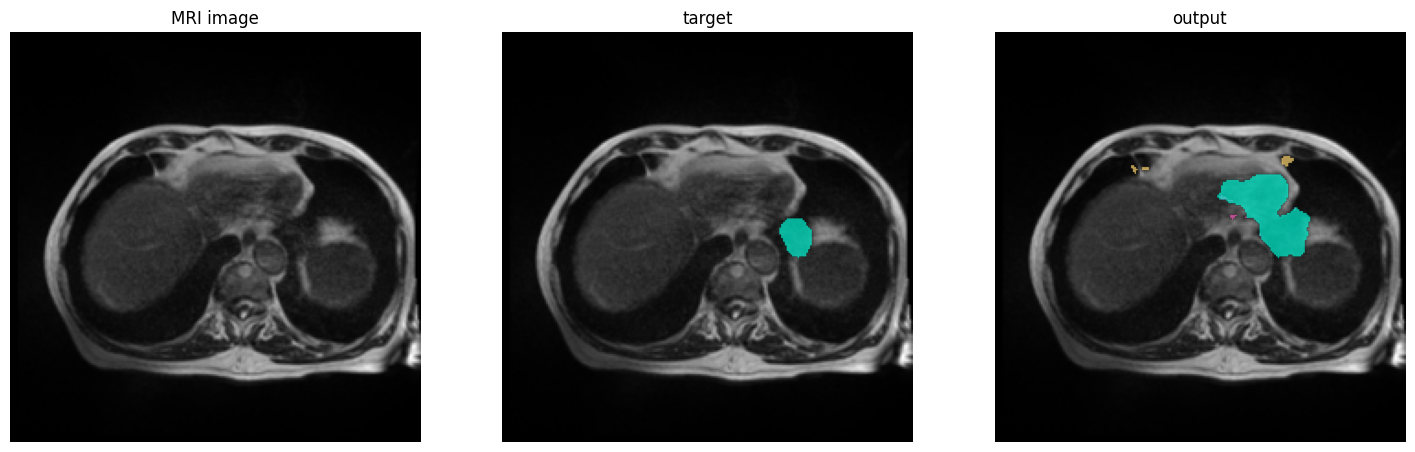

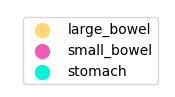

==================== DeepLabV3Plus ====================


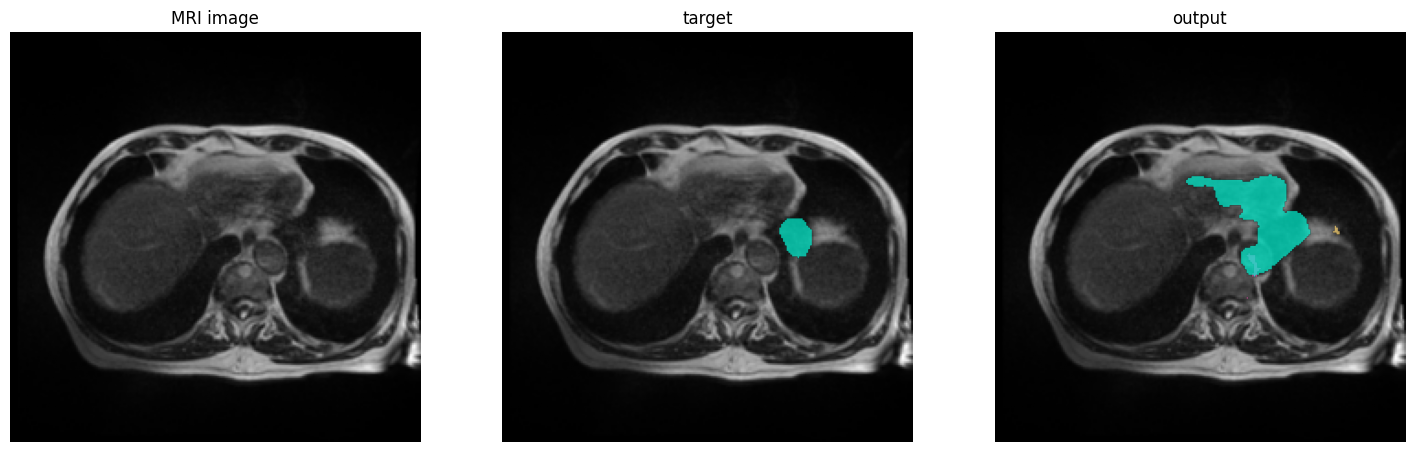

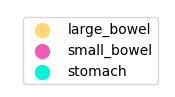

==================== SegFormer ====================


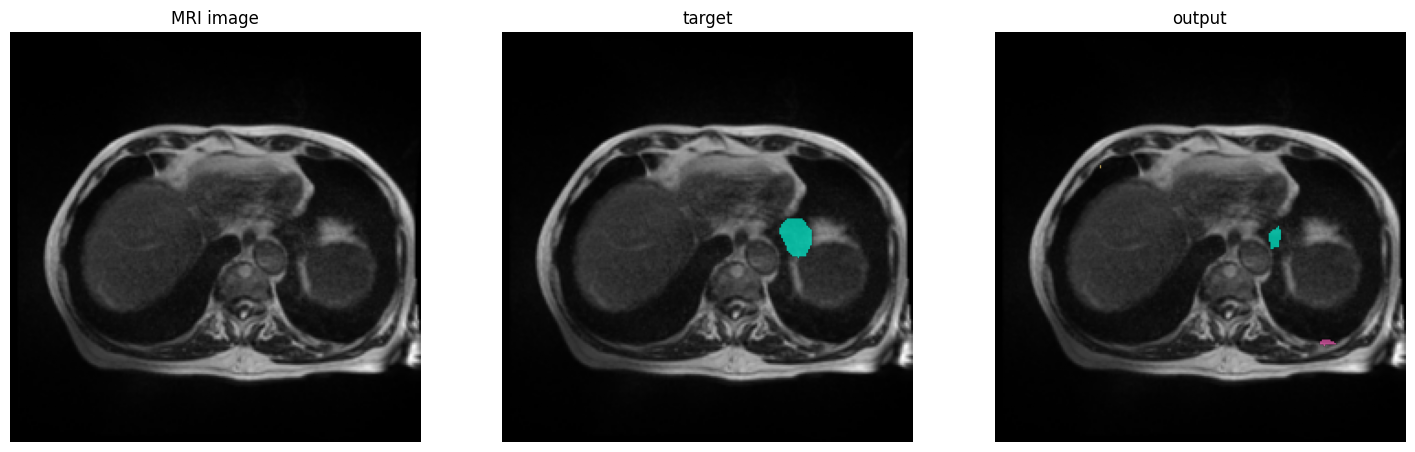

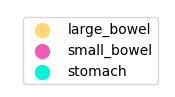

In [75]:
img, mask = next(iter(val_loader))
output_unet = segment(img.to(device), model_unet)
output_deeplabv3 = segment(img.to(device), model_deeplabv3)
output_sf = segment(img.to(device), model_sf)

print('='*20, 'UNet', '='*20)
model_output_show(img[0, 0], mask[0], output_unet[0])

print('='*20, 'DeepLabV3Plus', '='*20)
model_output_show(img[0, 0], mask[0], output_deeplabv3[0])

print('='*20, 'SegFormer', '='*20)
model_output_show(img[0, 0], mask[0], output_sf[0])